# Almost Complex Structure Analysis

This notebook loads trained models from the `outputs/` folder and produces
a battery of diagnostics designed to interrogate what
the network has learned.

**Five figures, each with a clear question:**

| # | Figure | Question answered |
|---|--------|-------------------|
| 1 | Training history | Did the network converge? Is Nijenhuis still decreasing? |
| 2 | Nijenhuis tensor heatmap on S^{2n} | *Where* on the sphere is J most/least integrable? |
| 3 | J² + I constraint · rotation from J₀ | Is J² = −I maintained? How much has J moved from the trivial solution? |
| 4 | Nijenhuis vs. rotation angle | Does larger rotation from J₀ help or hurt integrability? |
| 5 | Cross-patch consistency | Do the two charts describe the same global J? |

For **S⁶** the central question is whether the minimum of ‖N_J‖ approaches zero
(suggesting integrability) or plateaus at a strictly positive value (obstruction).
All plots are designed to make this legible.

In [16]:
# ── 0. Environment ────────────────────────────────────────────────────────────
import os
# Needed on Apple Silicon: torch.matrix_exp falls back to CPU gracefully.
os.environ.setdefault('PYTORCH_ENABLE_MPS_FALLBACK', '1')

import sys
sys.path.insert(0, os.path.abspath('.'))

import json
import yaml
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
from matplotlib.gridspec import GridSpec

from src.geometry.sphere import EvenSphere, RADIAL_MIDPOINT
from src.models.architecture import TwoPatchAlmostComplexNet, PatchSubNet

# Always evaluate on CPU: avoids the MPS matrix_exp limitation and keeps
# the notebook portable.  Evaluation on ~1000 points is fast regardless.
DEVICE = 'cpu'
torch.set_grad_enabled(True)   # needed for Nijenhuis autograd

plt.rcParams.update({
    'figure.dpi': 130,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
})
print('Setup complete.')


Setup complete.


## 1. Discover experiments

In [17]:
# ── 1. Discover experiments from outputs/ and extra/good_models/ ──────────────
OUTPUTS_DIR     = Path('outputs')
GOOD_MODELS_DIR = Path('extra/good_models')

SEARCH_DIRS = [
    (OUTPUTS_DIR,     'outputs'),
    (GOOD_MODELS_DIR, 'good_models'),
]

experiments = []

def _cfg_dim(cfg):
    """Return the real manifold dimension, handling old and new config formats."""
    geo = cfg['geometry']
    if 'real_dimension' in geo:
        return geo['real_dimension']
    if 'dimension' in geo:
        return geo['dimension']
    return geo['real_dimension_alpha'] + geo['real_dimension_beta']

def _cfg_manifold_type(cfg):
    return cfg['geometry'].get('manifold_type', 'sphere')

def _load_experiment(exp_dir, source):
    config_path = exp_dir / 'config.yaml'
    if not config_path.exists():
        return None
    with open(config_path) as f:
        cfg = yaml.safe_load(f)
    ckpt_dir  = exp_dir / 'checkpoints'
    best_ckpt = ckpt_dir / 'best_model.pt'
    all_ckpts = sorted(ckpt_dir.glob('*.pt')) if ckpt_dir.exists() else []
    loss_path = exp_dir / 'loss_data.json'
    loss_data = None
    if loss_path.exists():
        with open(loss_path) as f:
            loss_data = json.load(f)
    n_epochs  = len(loss_data['train']) if loss_data else 0
    test_info = loss_data.get('test', {}) if loss_data else {}
    return dict(
        name          = exp_dir.name,
        path          = exp_dir,
        source        = source,
        config        = cfg,
        dim           = _cfg_dim(cfg),
        manifold_type = _cfg_manifold_type(cfg),
        best_ckpt     = best_ckpt if best_ckpt.exists() else (all_ckpts[-1] if all_ckpts else None),
        all_ckpts     = all_ckpts,
        loss_data     = loss_data,
        n_epochs      = n_epochs,
        test_info     = test_info,
    )

for search_dir, source_tag in SEARCH_DIRS:
    if not search_dir.exists():
        print(f"[skip] {search_dir}/ not found.")
        continue
    for exp_dir in sorted(search_dir.iterdir()):
        if not exp_dir.is_dir():
            continue
        record = _load_experiment(exp_dir, source_tag)
        if record is not None:
            experiments.append(record)

if not experiments:
    raise RuntimeError(
        "No valid experiments found in 'outputs/' or 'extra/good_models/'.\n"
        "Run train.py first, or place a trained run in extra/good_models/."
    )

# ── Print selection table ──────────────────────────────────────────────────────
print(f"Found {len(experiments)} experiment(s).")
print("Use the Name or # index in the MODEL selector below.\n")

_SPHERE_LABEL = {2: 'S²  ', 4: 'S⁴  ', 6: 'S⁶  '}

prev_source = None
for i, exp in enumerate(experiments):
    if exp['source'] != prev_source:
        section = 'outputs/' if exp['source'] == 'outputs' else '★  extra/good_models/'
        print(f"── {section} {'─' * max(0, 56 - len(section))}")
        print(f"  {'#':<4}  {'Name':<26}  {'Sphere':<6}  {'Epochs':<7}  "
              f"{'Nij₁ mean (test)':<18}  {'Overlap (test)'}")
        print(f"  {'─'*4}  {'─'*26}  {'─'*6}  {'─'*7}  {'─'*18}  {'─'*14}")
        prev_source = exp['source']

    ti      = exp['test_info']
    nij_s   = f"{ti['nij1']:.3e}"          if 'nij1'         in ti else 'N/A'
    ov_s    = f"{ti['overlap_norm']:.3e}"   if 'overlap_norm' in ti else 'N/A'
    sphere  = (_SPHERE_LABEL.get(exp['dim'], f"S^{exp['dim']}") 
               if exp['manifold_type'] != 'sphere_product' else f"prod{exp['dim']}")
    print(f"  {i:<4}  {exp['name']:<26}  {sphere:<6}  {exp['n_epochs']:<7}  "
          f"{nij_s:<18}  {ov_s}")
print()


Found 7 experiment(s).
Use the Name or # index in the MODEL selector below.

── outputs/ ────────────────────────────────────────────────
  #     Name                        Sphere  Epochs   Nij₁ mean (test)    Overlap (test)
  ────  ──────────────────────────  ──────  ───────  ──────────────────  ──────────────
  0     20260309_185513             S²      6        1.803e+01           6.258e-02
  1     20260309_192012             S⁴      6        3.605e-01           2.843e+00
  2     20260309_192333             S⁶      6        2.051e-01           3.467e+00
── ★  extra/good_models/ ───────────────────────────────────
  #     Name                        Sphere  Epochs   Nij₁ mean (test)    Overlap (test)
  ────  ──────────────────────────  ──────  ───────  ──────────────────  ──────────────
  3     ACS_S2                      S²      101      -0.000e+00          6.221e-03
  4     ACS_S6                      S⁶      21       1.817e+01           2.488e-01
  5     fail_S4                   

## 2. Select and load a model

Set `MODEL` to the experiment **name** (the `Name` column above) or an **integer index**.

| Value | Picks |
|-------|-------|
| `'ACS_S2'` | ★ S² — best integrable result (`good_models`) |
| `'ACS_S6'` | ★ S⁶ — best low-Nijenhuis run (`good_models`) |
| `'fail_S4'` | ★ S⁴ — reference (no ACS exists) (`good_models`) |
| `'fail_S6'` | ★ S⁶ — earlier/failed run (`good_models`) |
| `'20260309_192333'` | a timestamped run from `outputs/` |
| `2` | third experiment by index |

Names are stable across re-runs; indices may shift if new experiments are added.


In [18]:
# ── 2. Load model ─────────────────────────────────────────────────────────────
# Set MODEL to an experiment name (string) or integer index from the table above.
#
#   ★ good_models — curated runs:
#       MODEL = 'ACS_S2'    # S²  known integrable,  Nij → 0
#       MODEL = 'ACS_S6'    # S⁶  best low-Nijenhuis run found so far
#       MODEL = 'fail_S4'   # S⁴  reference: no ACS exists on this sphere
#       MODEL = 'fail_S6'   # S⁶  earlier run that plateaued / was stopped early
#
#   outputs/ — your local training runs (use the timestamp folder name):
#       MODEL = '20260309_185513'
#       MODEL = '20260309_192012'
#       MODEL = '20260309_192333'
#
#   Or use an integer index from the '#' column in the table above:
#       MODEL = 0

MODEL = 'ACS_S6'   # ← change this

# ── Resolve selection ──────────────────────────────────────────────────────────
if isinstance(MODEL, int):
    if MODEL < 0 or MODEL >= len(experiments):
        raise IndexError(f"MODEL={MODEL} is out of range (0–{len(experiments)-1}).")
    exp = experiments[MODEL]
elif isinstance(MODEL, str):
    matches = [e for e in experiments if e['name'] == MODEL]
    if not matches:
        available = [e['name'] for e in experiments]
        raise ValueError(
            f"No experiment named {MODEL!r}.\n"
            f"Available names: {available}"
        )
    exp = matches[0]
else:
    raise TypeError(f"MODEL must be a string name or integer index, got {type(MODEL).__name__!r}")

cfg     = exp['config']
DIM     = exp['dim']
net_cfg = cfg['network']

model = TwoPatchAlmostComplexNet(
    manifold_dim        = DIM,
    hidden_layers       = net_cfg['hidden_layers'],
    activation          = net_cfg['activation'],
    use_fourier_features= net_cfg['use_fourier_features'],
    num_fourier_features= net_cfg['num_fourier_features'],
    fourier_scale       = net_cfg['fourier_scale'],
    initialization      = net_cfg['initialization'],
    matrix_exp_terms    = net_cfg.get('matrix_exp_terms'),
).to(DEVICE)

ckpt = torch.load(exp['best_ckpt'], map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt['model_state_dict'])
model.eval()

sphere = EvenSphere(dimension=DIM, device=DEVICE)

src_tag = '★ good_models' if exp['source'] == 'good_models' else 'outputs'
print(f"Experiment : {exp['name']}  [{src_tag}]")
print(f"Manifold   : S^{DIM}  (complex dimension {DIM//2})")
print(f"Checkpoint : {exp['best_ckpt'].name}  at epoch {ckpt['epoch']}")
print(f"Best loss  : {ckpt['best_loss']:.6e}")
print(f"Parameters : {sum(p.numel() for p in model.parameters()):,}")


Experiment : ACS_S6  [★ good_models]
Manifold   : S^6  (complex dimension 3)
Checkpoint : best_model.pt  at epoch 160
Best loss  : 5.263747e-01
Parameters : 1,063,972


## 3. Helper functions

All heavy computation is isolated here; plotting cells are pure matplotlib.

In [6]:
# ── 3. Helper functions ───────────────────────────────────────────────────────

def compute_nijenhuis_norms(subnet: PatchSubNet, x: torch.Tensor,
                            chunk: int = 100):
    """
    Return (J, nij_norm) for a batch of patch coordinates.

    Computes the coordinate-expression of the Nijenhuis tensor
        N^k_{ij} = J^l_i ∂_l J^k_j − J^l_j ∂_l J^k_i + J^k_l(∂_i J^l_j − ∂_j J^l_i)
    via autograd in mini-batches, returns both J (batch,d,d) and ‖N‖ (batch,).
    """
    Js, norms = [], []
    for start in range(0, len(x), chunk):
        xc = x[start:start+chunk].detach().requires_grad_(True)
        J  = subnet(xc)               # (chunk, d, d)
        d  = J.shape[1]

        rows = []
        for k in range(d):
            cols = []
            for j in range(d):
                g = torch.autograd.grad(
                    J[:, k, j].sum(), xc,
                    create_graph=False, retain_graph=True,
                )[0]               # (chunk, d)
                cols.append(g)
            rows.append(torch.stack(cols, dim=1))   # (chunk, d, d)
        dJ = torch.stack(rows, dim=1)               # (chunk, d, d, d)

        term1 = torch.einsum('bli,bkjl->bkij', J, dJ)
        term2 = -torch.einsum('blj,bkil->bkij', J, dJ)
        anti  = dJ.permute(0, 1, 3, 2) - dJ
        term3 = torch.einsum('bkl,blij->bkij', J, anti)
        N     = term1 + term2 + term3

        Js.append(J.detach())
        norms.append(torch.sqrt((N**2).sum(dim=(1,2,3)) + 1e-14).detach())

    return torch.cat(Js, 0), torch.cat(norms, 0)


def ambient_coords(x1: torch.Tensor):
    """
    Map patch-1 ball coordinates → ambient sphere R^{2n+1}.
    Returns numpy array shape (batch, 2n+1).
    """
    return EvenSphere.ball_to_sphere(x1, from_north=True).detach().cpu().numpy()


def equirectangular(amb):
    """
    Project ambient sphere coords to (longitude, latitude) in radians.
    Works for S^{2n}: latitude uses the *last* ambient coordinate
    (the stereographic 'height'), longitude uses the first two equatorial ones.
    """
    lat = np.arcsin(np.clip(amb[:, -1], -1.0, 1.0))
    lon = np.arctan2(amb[:, 1], amb[:, 0])
    return lon, lat


def j2_violation(J: torch.Tensor):
    """Per-point ‖J² + I‖_F — should be O(1e-6) by construction."""
    d   = J.shape[1]
    I   = torch.eye(d, device=J.device).unsqueeze(0)
    J2  = torch.bmm(J, J)
    return torch.sqrt(((J2 + I)**2).sum(dim=(1,2))).detach().cpu().numpy()


def rotation_angle(J: torch.Tensor, J0_signed: torch.Tensor):
    """
    Rotation angle (radians) between the learned J and the reference J₀.

        θ(x) = arccos( Tr(J(x)ᵀ J₀) / d )

    For J satisfying J² = -I and any J₀ with J₀² = -I, this equals the
    geodesic distance on the space of almost complex structures (up to scale).
    θ = 0  ↔  J = J₀  (no rotation, trivial solution)
    θ = π  ↔  J = -J₀
    """
    d = J.shape[1]
    # Frobenius inner product <J, J0> = Tr(Jᵀ J0)
    inner = torch.einsum('bij,ij->b', J, J0_signed)   # (batch,)
    cos_t = (inner / d).clamp(-1.0, 1.0)
    return torch.acos(cos_t).detach().cpu().numpy()


def overlap_error_radial(J1, J2, x1, x2):
    """
    Per-point cross-patch consistency error ‖J1→2 − J2‖_F,
    plus the patch-1 radii, for scatter/profile plotting.
    """
    F   = EvenSphere.patch_change_jacobian(x1)          # (batch, d, d)
    Fin = torch.linalg.inv(F)
    J1_to_2 = F @ J1 @ Fin                              # (batch, d, d)
    diff   = J1_to_2 - J2
    err    = torch.sqrt((diff**2).sum(dim=(1,2)) + 1e-14).detach().cpu().numpy()
    rho    = x1.norm(dim=1).detach().cpu().numpy()
    return rho, err


print('Helpers defined.')

Helpers defined.


## 4. Compute diagnostics

All the (slow) autograd-based computations live here.  
Increase `N_SAMPLES` for sharper plots — 500 is fast, 3000 gives publication quality.

In [7]:
# ── 4. Sample and compute everything ─────────────────────────────────────────
N_SAMPLES = 10000   # 10000 for good plots

print(f'Sampling {N_SAMPLES} points on S^{DIM}...')
x1 = sphere.sample_points_patch1(N_SAMPLES).to(DEVICE)
x2 = EvenSphere.patch_change_coords(x1)       # patch-2 coordinates

# Forward pass (no Nijenhuis yet)
with torch.no_grad():
    J1_all, J2_all, _, _ = model(x1)

# Ambient coords and 2-D projection
amb = ambient_coords(x1)
lon, lat = equirectangular(amb)

# Radii in patch-1 and patch-2
rho1 = x1.norm(dim=1).detach().cpu().numpy()
rho2 = x2.norm(dim=1).detach().cpu().numpy()

# J² + I constraint quality
constraint_err = j2_violation(J1_all)

# Rotation angle from J₀  (use J₀_signed from each subnet)
J0_p1 = model.patch1.J0.to(DEVICE)   # +J₀  (patch 1)
J0_p2 = model.patch2.J0.to(DEVICE)   # -J₀  (patch 2)
rot_angle_p1 = rotation_angle(J1_all, J0_p1)   # for patch-1 points

# Cross-patch consistency
rho_ov, overlap_err = overlap_error_radial(J1_all, J2_all, x1, x2)

# Nijenhuis norms (slow — runs autograd)
print(f'Computing Nijenhuis tensor for patch 1...  (d={DIM}, {N_SAMPLES} pts)')
_, nij_p1 = compute_nijenhuis_norms(model.patch1, x1, chunk=100)
nij_p1 = nij_p1.numpy()

print(f'Computing Nijenhuis tensor for patch 2...')
_, nij_p2 = compute_nijenhuis_norms(model.patch2, x2, chunk=100)
nij_p2 = nij_p2.numpy()

# 'Global' Nijenhuis: use the dominant patch at each point
# (patch 1 for small rho, patch 2 — mapped back — for large rho)
use_p1 = rho1 <= RADIAL_MIDPOINT
nij_global = np.where(use_p1, nij_p1, nij_p2)

print('─' * 50)
print(f'  ‖N_J‖ patch 1  —  mean: {nij_p1.mean():.4e}   max: {nij_p1.max():.4e}')
print(f'  ‖N_J‖ patch 2  —  mean: {nij_p2.mean():.4e}   max: {nij_p2.max():.4e}')
print(f'  ‖J²+I‖         —  mean: {constraint_err.mean():.2e}   max: {constraint_err.max():.2e}')
print(f'  θ from J₀      —  mean: {np.degrees(rot_angle_p1.mean()):.2f}°   '
      f'max: {np.degrees(rot_angle_p1.max()):.2f}°')
print(f'  overlap error  —  mean: {overlap_err.mean():.4e}   max: {overlap_err.max():.4e}')

Sampling 10000 points on S^4...
Computing Nijenhuis tensor for patch 1...  (d=4, 10000 pts)
Computing Nijenhuis tensor for patch 2...
──────────────────────────────────────────────────
  ‖N_J‖ patch 1  —  mean: 4.1463e+00   max: 5.0353e+00
  ‖N_J‖ patch 2  —  mean: 3.4393e+00   max: 3.7388e+00
  ‖J²+I‖         —  mean: 4.40e-07   max: 1.43e-06
  θ from J₀      —  mean: 0.00°   max: 0.00°
  overlap error  —  mean: 8.1219e+00   max: 2.0252e+03


## Fig. 1 — Training history

**What to look for:** Is the total loss still falling?  
For S⁶, the Nijenhuis component dominates; you want to see it decreasing monotonically.  
A plateau suggests the network has found a local minimum — possibly a geometric obstruction.

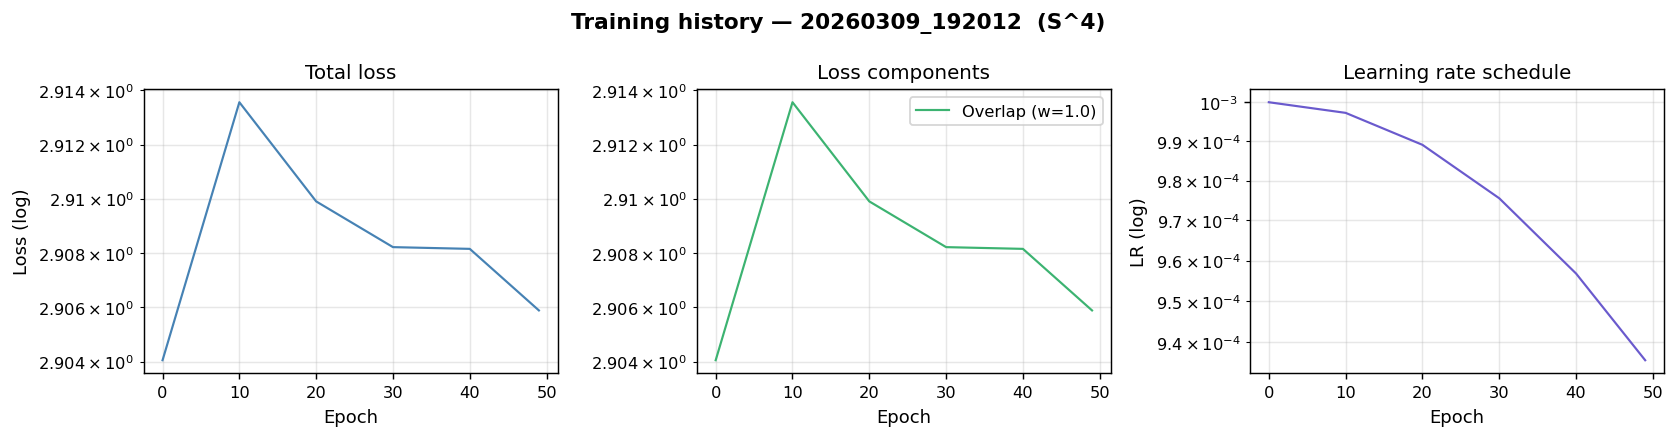

In [8]:
# ── Fig. 1: Training history ──────────────────────────────────────────────────
ld = exp['loss_data']
if not ld or not ld.get('train'):
    print('No loss_data.json found — skipping figure 1.')
else:
    train = ld['train']
    epochs     = [r['epoch']      for r in train]
    total_loss = [r['total_loss'] for r in train]
    nij1       = [r.get('nij1', 0)         for r in train]
    nij2       = [r.get('nij2', 0)         for r in train]
    overlap    = [r.get('overlap_norm', 0) for r in train]
    lr_vals    = [r.get('lr', float('nan')) for r in train]
    nij_total  = [a + b for a, b in zip(nij1, nij2)]

    val = ld.get('val', [])
    val_epochs = [r['epoch'] for r in val]
    val_total  = [r['total_loss'] for r in val]

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
    fig.suptitle(f'Training history — {exp["name"]}  (S^{DIM})', fontweight='bold')

    # Panel A: total loss
    ax = axes[0]
    ax.semilogy(epochs, total_loss, lw=1.2, color='steelblue', label='train')
    if val:
        ax.semilogy(val_epochs, val_total, lw=1.2, color='tomato', ls='--', label='val')
        ax.legend(loc='upper right')
    ax.set_title('Total loss')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss (log)')
    ax.grid(True, which='both', alpha=0.3)

    # Panel B: loss decomposition
    ax = axes[1]
    lw_cfg = cfg.get('loss_weights', {})
    w_nij = lw_cfg.get('nijenhuis', 1.0)
    w_ov  = lw_cfg.get('overlap',   1.0)
    if w_nij > 0:
        ax.semilogy(epochs, nij_total, lw=1.2, color='orangered',
                    label=f'Nijenhuis (w={w_nij})')
    ax.semilogy(epochs, overlap, lw=1.2, color='mediumseagreen',
                label=f'Overlap (w={w_ov})')
    ax.set_title('Loss components')
    ax.set_xlabel('Epoch')
    ax.legend(loc='upper right')
    ax.grid(True, which='both', alpha=0.3)

    # Panel C: learning rate
    ax = axes[2]
    ax.semilogy(epochs, lr_vals, lw=1.2, color='slateblue')
    ax.set_title('Learning rate schedule')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('LR (log)')
    ax.grid(True, which='both', alpha=0.3)

    plt.tight_layout()
    plt.savefig(exp['path'] / 'fig1_training_history.pdf', bbox_inches='tight')
    plt.show()

## Fig. 2 — Nijenhuis tensor norm on S^{2n}

**Projection:** equirectangular — latitude from the last ambient coordinate,  
longitude from the first two.  For S^{2n} with n > 1 this projection discards  
information in the other equatorial directions, but it captures the north–south  
and east–west structure clearly.

**What to look for:**  
- **Uniform colour** → obstruction is spread evenly; no preferred direction.  
- **Latitudinal banding** → equatorial vs. polar regions contribute differently.  
- **Isolated hot spots** → localised obstruction or numerical artefact near the patch boundary.  
- **Overall colour level** → how far is ‖N_J‖ from zero?  On S² the palette should be near the bottom.

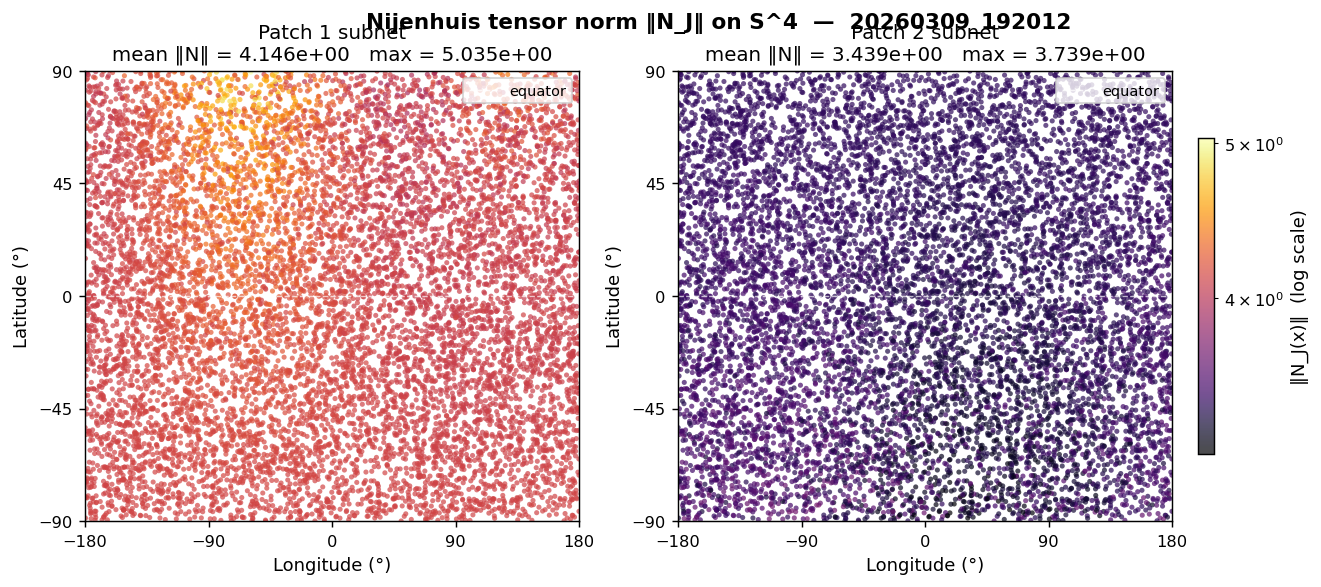

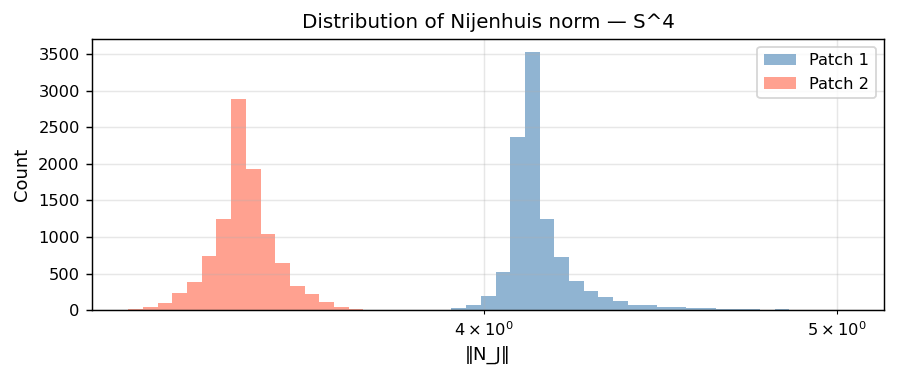

In [9]:
# ── Fig. 2: Nijenhuis heatmap on the sphere ──────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
fig.suptitle(
    f'Nijenhuis tensor norm ‖N_J‖ on S^{DIM}  —  {exp["name"]}',
    fontweight='bold'
)

# Shared colour scale (log) across both patches
all_nij = np.concatenate([nij_p1, nij_p2])
vmin = max(all_nij.min(), 1e-6)
vmax = all_nij.max()
norm_log = mcolors.LogNorm(vmin=vmin, vmax=vmax)
cmap = 'inferno'

for ax, nij, patch_id, rho in [
    (axes[0], nij_p1, 1, rho1),
    (axes[1], nij_p2, 2, rho2),
]:
    sc = ax.scatter(
        np.degrees(lon), np.degrees(lat),
        c=nij, cmap=cmap, norm=norm_log,
        s=8, alpha=0.7, linewidths=0,
    )
    # Mark equatorial belt
    eq_lat = np.degrees(np.arcsin(np.clip(
        EvenSphere.ball_to_sphere(
            torch.full((1, DIM), RADIAL_MIDPOINT) / DIM**0.5 * DIM**0.5
        ).squeeze()[-1].item(), -1, 1
    )))
    ax.axhline(0, color='white', lw=0.8, ls='--', alpha=0.7, label='equator')
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    ax.set_xticks([-180, -90, 0, 90, 180])
    ax.set_yticks([-90, -45, 0, 45, 90])
    ax.set_xlabel('Longitude (°)')
    ax.set_ylabel('Latitude (°)')
    ax.set_title(
        f'Patch {patch_id} subnet\n'
        f'mean ‖N‖ = {nij.mean():.3e}   max = {nij.max():.3e}'
    )
    ax.legend(fontsize=8, loc='upper right')

fig.colorbar(sc, ax=axes, label='‖N_J(x)‖  (log scale)', shrink=0.7, pad=0.02)
plt.savefig(exp['path'] / 'fig2_nijenhuis_heatmap.pdf', bbox_inches='tight')
plt.show()

# Side-by-side histogram for quantitative comparison
fig, ax = plt.subplots(figsize=(7, 3))
bins = np.logspace(np.log10(vmin), np.log10(vmax), 50)
ax.hist(nij_p1, bins=bins, alpha=0.6, color='steelblue', label='Patch 1')
ax.hist(nij_p2, bins=bins, alpha=0.6, color='tomato',    label='Patch 2')
ax.set_xscale('log')
ax.set_xlabel('‖N_J‖')
ax.set_ylabel('Count')
ax.set_title(f'Distribution of Nijenhuis norm — S^{DIM}')
ax.legend()
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.savefig(exp['path'] / 'fig2b_nijenhuis_hist.pdf', bbox_inches='tight')
plt.show()

## Fig. 3 — Constraint quality and rotation from J₀

**Left:** ‖J(x)² + I‖_F per sample.  
By construction (matrix-exponential parametrisation) this should be at most O(1e-5) — floating-point
rounding noise.  Any value substantially above 1e-4 signals a numerical issue.

**Right:** the *rotation angle* θ(x) = arccos(⟨J(x), J₀⟩_F / d) in degrees.  
This measures how far the learned J is from the canonical (trivial) structure J₀.
- **θ ≈ 0° everywhere** → the network barely moved J from J₀.
- **Spatially varying θ** → J is genuinely position-dependent and non-trivial.
- A large and *spatially non-uniform* θ combined with a small ‖N_J‖ is good.

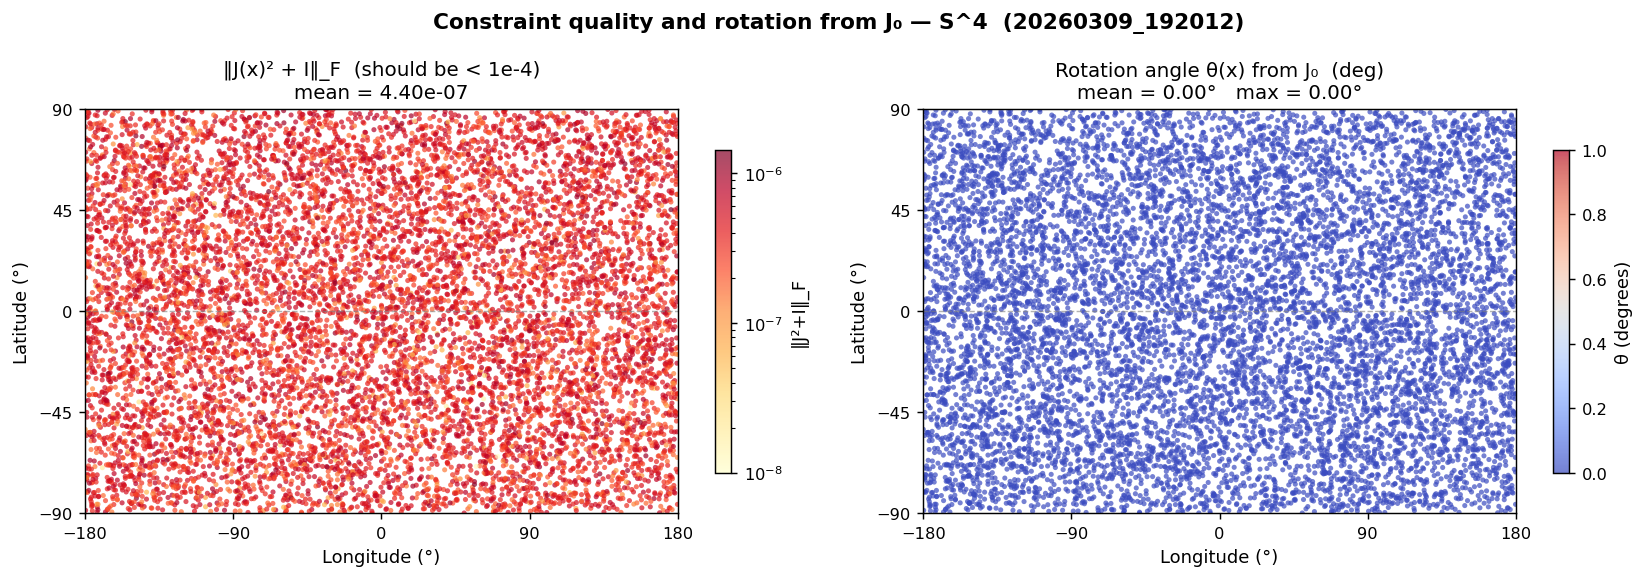

In [10]:
# ── Fig. 3: J²+I constraint and rotation angle ────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
fig.suptitle(
    f'Constraint quality and rotation from J₀ — S^{DIM}  ({exp["name"]})',
    fontweight='bold'
)

# Panel A: J²+I constraint (should be ~machine precision)
ax = axes[0]
sc = ax.scatter(
    np.degrees(lon), np.degrees(lat),
    c=constraint_err,
    cmap='YlOrRd',
    norm=mcolors.LogNorm(
        vmin=max(constraint_err.min(), 1e-8),
        vmax=constraint_err.max()
    ),
    s=8, alpha=0.7, linewidths=0,
)
ax.axhline(0, color='grey', lw=0.8, ls='--', alpha=0.6)
ax.set_xlim(-180, 180); ax.set_ylim(-90, 90)
ax.set_xticks([-180, -90, 0, 90, 180])
ax.set_yticks([-90, -45, 0, 45, 90])
ax.set_xlabel('Longitude (°)'); ax.set_ylabel('Latitude (°)')
ax.set_title(f'‖J(x)² + I‖_F  (should be < 1e-4)\nmean = {constraint_err.mean():.2e}')
fig.colorbar(sc, ax=ax, label='‖J²+I‖_F', shrink=0.8)

# Panel B: rotation angle θ from J₀
ax = axes[1]
rot_deg = np.degrees(rot_angle_p1)
sc = ax.scatter(
    np.degrees(lon), np.degrees(lat),
    c=rot_deg,
    cmap='coolwarm',
    vmin=0, vmax=max(rot_deg.max(), 1.0),
    s=8, alpha=0.7, linewidths=0,
)
ax.axhline(0, color='grey', lw=0.8, ls='--', alpha=0.6)
ax.set_xlim(-180, 180); ax.set_ylim(-90, 90)
ax.set_xticks([-180, -90, 0, 90, 180])
ax.set_yticks([-90, -45, 0, 45, 90])
ax.set_xlabel('Longitude (°)'); ax.set_ylabel('Latitude (°)')
ax.set_title(
    f'Rotation angle θ(x) from J₀  (deg)\n'
    f'mean = {rot_deg.mean():.2f}°   max = {rot_deg.max():.2f}°'
)
fig.colorbar(sc, ax=ax, label='θ (degrees)', shrink=0.8)

plt.tight_layout()
plt.savefig(exp['path'] / 'fig3_constraint_rotation.pdf', bbox_inches='tight')
plt.show()

## Fig. 4 — Nijenhuis norm vs. rotation angle

**The central scatter plot.**  Each dot is one sample point on S^{2n}:
- **x-axis:** rotation angle θ from J₀ (how much J has been deformed)
- **y-axis:** ‖N_J‖ (how far from integrable)
- **colour:** patch-1 radius ρ (distinguishes poles from equator)

This plot diagnoses *what the optimizer found*:

| Pattern | Interpretation |
|---------|----------------|
| Points cluster near (0, high ‖N‖) | Network stayed near trivial J₀ |
| Negative ‖N‖–θ trend | More rotation → less Nijenhuis; optimizer is on the right track |
| Points at large θ still have large ‖N‖ | Rotation alone is not the key; the structure of the obstruction is richer |
| Cloud concentrated near y ≈ 0 | Very small Nijenhuis achieved (integrable candidate found) |

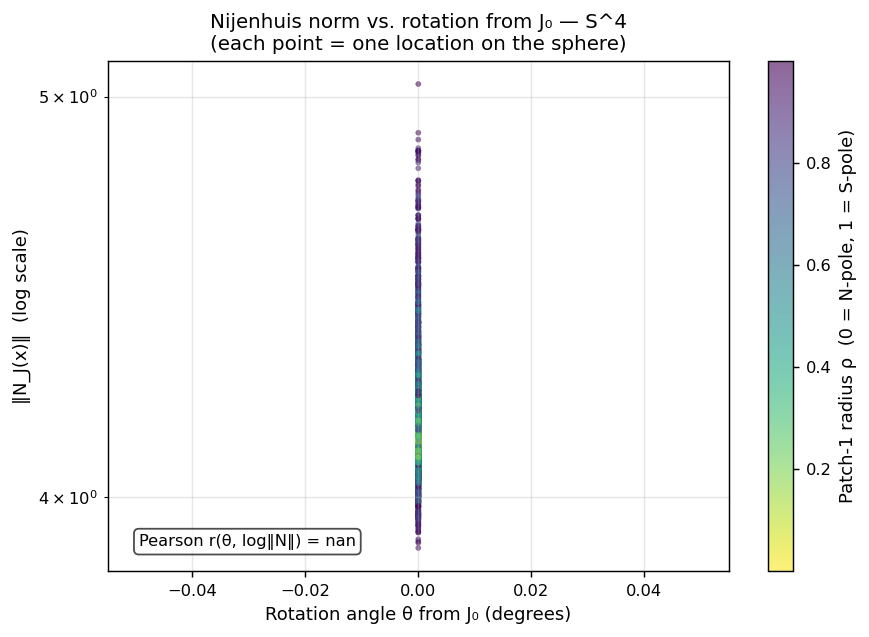

In [11]:
# ── Fig. 4: Nijenhuis vs rotation scatter ─────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 5))

sc = ax.scatter(
    np.degrees(rot_angle_p1), nij_p1,
    c=rho1, cmap='viridis_r',
    s=10, alpha=0.6, linewidths=0,
)
fig.colorbar(sc, ax=ax, label='Patch-1 radius ρ  (0 = N-pole, 1 = S-pole)')

ax.set_yscale('log')
ax.set_xlabel('Rotation angle θ from J₀ (degrees)')
ax.set_ylabel('‖N_J(x)‖  (log scale)')
ax.set_title(
    f'Nijenhuis norm vs. rotation from J₀ — S^{DIM}\n'
    '(each point = one location on the sphere)'
)
ax.grid(True, which='both', alpha=0.3)

# Add Pearson correlation annotation
corr = np.corrcoef(rot_angle_p1, np.log10(nij_p1 + 1e-14))[0, 1]
ax.text(0.05, 0.05, f'Pearson r(θ, log‖N‖) = {corr:.3f}',
        transform=ax.transAxes, fontsize=9,
        bbox=dict(boxstyle='round', fc='white', alpha=0.7))

plt.tight_layout()
plt.savefig(exp['path'] / 'fig4_nijenhuis_vs_rotation.pdf', bbox_inches='tight')
plt.show()

## Fig. 5 — Cross-patch consistency

J is only a *globally* well-defined tensor if the two chart descriptions agree in the overlap band.  
This figure checks that.

**Left:** overlap error ‖J₁→₂ − J₂‖_F vs. radius ρ₁.  
The dashed verticals mark the equatorial belt [r_inner, r_outer]; the error should  
be largest there (where the charts overlap) and irrelevant outside it.  

**Right:** the same error mapped back to the sphere — shows whether inconsistency  
is uniform or localised at particular longitudes/latitudes.

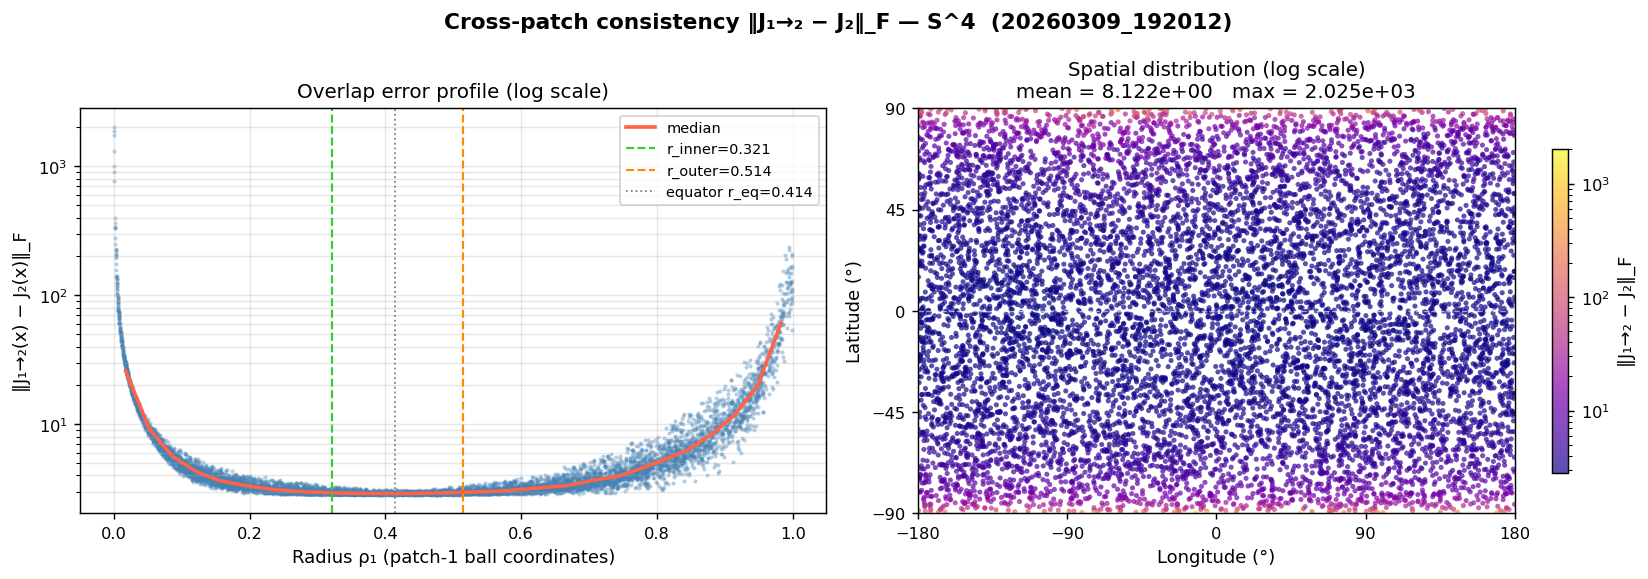

In [12]:
# ── Fig. 5: Cross-patch consistency ───────────────────────────────────────────
overlap_size = cfg.get('loss_weights', {}).get('overlap_size', 0.1)
r_outer = RADIAL_MIDPOINT + overlap_size
r_inner = (1.0 - r_outer) / (1.0 + r_outer)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
fig.suptitle(
    f'Cross-patch consistency ‖J₁→₂ − J₂‖_F — S^{DIM}  ({exp["name"]})',
    fontweight='bold'
)

# Panel A: error vs radius profile
ax = axes[0]
ax.scatter(rho_ov, overlap_err, s=5, alpha=0.4, color='steelblue', linewidths=0)

# Median trend line
rho_bins  = np.linspace(0, 1, 30)
bin_idx   = np.digitize(rho_ov, rho_bins)
med_vals  = [np.median(overlap_err[bin_idx == b]) for b in range(1, len(rho_bins))]
rho_cents = 0.5 * (rho_bins[:-1] + rho_bins[1:])
ax.plot(rho_cents, med_vals, color='tomato', lw=2, label='median')

ax.axvline(r_inner, color='limegreen', ls='--', lw=1.2, label=f'r_inner={r_inner:.3f}')
ax.axvline(r_outer, color='darkorange', ls='--', lw=1.2, label=f'r_outer={r_outer:.3f}')
ax.axvline(RADIAL_MIDPOINT, color='grey', ls=':', lw=1.0, label=f'equator r_eq={RADIAL_MIDPOINT:.3f}')
ax.set_yscale('log')
ax.set_xlabel('Radius ρ₁ (patch-1 ball coordinates)')
ax.set_ylabel('‖J₁→₂(x) − J₂(x)‖_F')
ax.set_title('Overlap error profile (log scale)')
ax.legend(fontsize=8)
ax.grid(True, which='both', alpha=0.3)

# Panel B: spatial heatmap of overlap error
ax = axes[1]
ov_min = max(overlap_err.min(), 1e-8)
sc = ax.scatter(
    np.degrees(lon), np.degrees(lat),
    c=overlap_err,
    cmap='plasma',
    norm=mcolors.LogNorm(vmin=ov_min, vmax=overlap_err.max()),
    s=8, alpha=0.7, linewidths=0,
)
ax.axhline(0, color='white', lw=0.8, ls='--', alpha=0.6)
ax.set_xlim(-180, 180); ax.set_ylim(-90, 90)
ax.set_xticks([-180, -90, 0, 90, 180])
ax.set_yticks([-90, -45, 0, 45, 90])
ax.set_xlabel('Longitude (°)'); ax.set_ylabel('Latitude (°)')
ax.set_title(
    f'Spatial distribution (log scale)\n'
    f'mean = {overlap_err.mean():.3e}   max = {overlap_err.max():.3e}'
)
fig.colorbar(sc, ax=ax, label='‖J₁→₂ − J₂‖_F', shrink=0.8)

plt.tight_layout()
plt.savefig(exp['path'] / 'fig5_overlap_consistency.pdf', bbox_inches='tight')
plt.show()

## Fig. 6 — Multi-experiment comparison

If you have run training on multiple spheres or with different configurations,  
this cell produces a comparative bar chart of the test-set Nijenhuis norms.

**Key reference points:**
- **S²:** known to be integrable; ‖N_J‖ should converge to 0 (but the config sets `nijenhuis_weight=0`,  
  so the S² model trains only on overlap — it will still report ‖N_J‖ at test time).  
- **S⁴:** provably has *no* almost complex structure; overlap loss cannot go to zero.  
- **S⁶:** the open question; any reduction in ‖N_J‖ is scientifically interesting.

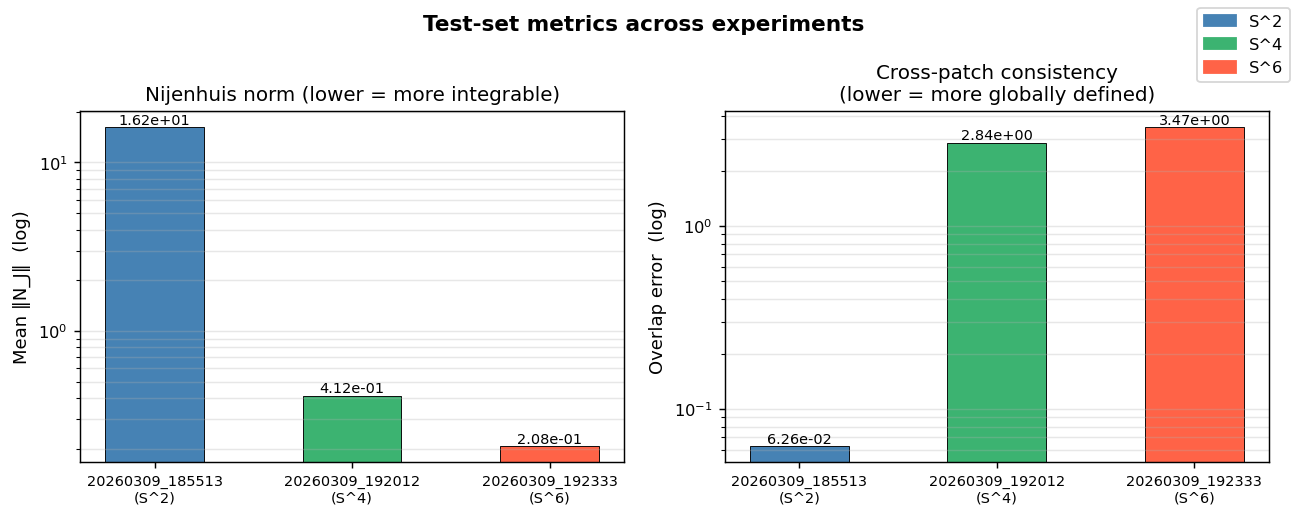

In [13]:
# ── Fig. 6: Multi-experiment comparison ───────────────────────────────────────
exps_with_test = [
    e for e in experiments if 'nij1' in e['test_info']
]

if len(exps_with_test) < 2:
    print('Only one experiment with test data — skipping comparison figure.\n'
          'Train on more spheres to populate this plot.')
else:
    labels = [f"{e['name']}\n(S^{e['dim']})" for e in exps_with_test]
    nij_vals = [
        (e['test_info']['nij1'] + e['test_info'].get('nij2', e['test_info']['nij1'])) / 2
        for e in exps_with_test
    ]
    ov_vals = [e['test_info'].get('overlap_norm', 0) for e in exps_with_test]

    dim_colors = {2: 'steelblue', 4: 'mediumseagreen', 6: 'tomato'}
    colors = [dim_colors.get(e['dim'], 'grey') for e in exps_with_test]

    fig, axes = plt.subplots(1, 2, figsize=(max(10, 3 * len(exps_with_test)), 4))
    fig.suptitle('Test-set metrics across experiments', fontweight='bold')

    x = np.arange(len(labels))

    ax = axes[0]
    bars = ax.bar(x, nij_vals, color=colors, width=0.5, edgecolor='k', lw=0.5)
    ax.bar_label(bars, fmt='%.2e', fontsize=8)
    ax.set_yscale('log')
    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8)
    ax.set_ylabel('Mean ‖N_J‖  (log)')
    ax.set_title('Nijenhuis norm (lower = more integrable)')
    ax.grid(True, axis='y', which='both', alpha=0.3)

    ax = axes[1]
    bars = ax.bar(x, ov_vals, color=colors, width=0.5, edgecolor='k', lw=0.5)
    ax.bar_label(bars, fmt='%.2e', fontsize=8)
    ax.set_yscale('log')
    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8)
    ax.set_ylabel('Overlap error  (log)')
    ax.set_title('Cross-patch consistency\n(lower = more globally defined)')
    ax.grid(True, axis='y', which='both', alpha=0.3)

    # Legend for sphere dimensions
    from matplotlib.patches import Patch
    handles = [Patch(color=v, label=f'S^{k}') for k, v in dim_colors.items()]
    fig.legend(handles=handles, loc='upper right', fontsize=9)

    plt.tight_layout()
    plt.savefig(OUTPUTS_DIR / 'fig6_comparison.pdf', bbox_inches='tight')
    plt.show()

## Summary table

In [14]:
# ── Summary printout ─────────────────────────────────────────────────────────
print('=' * 62)
print(f'  Summary: {exp["name"]}  —  S^{DIM}')
print('=' * 62)
print(f'  Checkpoint epoch         : {ckpt["epoch"]}')
print(f'  Best training loss       : {ckpt["best_loss"]:.6e}')
print()
print(f'  ‖N_J‖  patch 1  mean     : {nij_p1.mean():.6e}')
print(f'  ‖N_J‖  patch 1  max      : {nij_p1.max():.6e}')
print(f'  ‖N_J‖  patch 2  mean     : {nij_p2.mean():.6e}')
print(f'  ‖N_J‖  patch 2  max      : {nij_p2.max():.6e}')
print()
print(f'  ‖J²+I‖_F        mean     : {constraint_err.mean():.2e}  (should be <1e-4)')
print(f'  ‖J²+I‖_F        max      : {constraint_err.max():.2e}')
print()
print(f'  Rotation from J₀  mean   : {np.degrees(rot_angle_p1.mean()):.3f}°')
print(f'  Rotation from J₀  max    : {np.degrees(rot_angle_p1.max()):.3f}°')
print()
print(f'  Overlap error     mean   : {overlap_err.mean():.6e}')
print(f'  Overlap error     max    : {overlap_err.max():.6e}')
print('=' * 62)

if DIM == 6:
    print()
    print('  S⁶ note: integrability requires ‖N_J‖ → 0 everywhere.')
    nij_near_zero = (nij_p1 < 1e-2).mean() * 100
    print(f'  Fraction of patch-1 points with ‖N_J‖ < 1e-2 : {nij_near_zero:.1f}%')
    nij_near_zero2 = (nij_p1 < 1e-1).mean() * 100
    print(f'  Fraction of patch-1 points with ‖N_J‖ < 1e-1 : {nij_near_zero2:.1f}%')

  Summary: 20260309_192012  —  S^4
  Checkpoint epoch         : 0
  Best training loss       : 2.904058e+00

  ‖N_J‖  patch 1  mean     : 4.146332e+00
  ‖N_J‖  patch 1  max      : 5.035313e+00
  ‖N_J‖  patch 2  mean     : 3.439292e+00
  ‖N_J‖  patch 2  max      : 3.738789e+00

  ‖J²+I‖_F        mean     : 4.40e-07  (should be <1e-4)
  ‖J²+I‖_F        max      : 1.43e-06

  Rotation from J₀  mean   : 0.000°
  Rotation from J₀  max    : 0.000°

  Overlap error     mean   : 8.121905e+00
  Overlap error     max    : 2.025213e+03
